# Data Preprocessing and Exploration

## initial data inspection and loading

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("~/Documents/PlayTime/LMD_Modelling/data/raw/Dataset_90.csv")

df.head()

,sample_id,Power,Speed,Feed,width_um,height_um,depth_um,angle_deg,porosity_%,pore_count,pore_area_um2,meltpool_area_um2,bbox_xyxy
0,1.0_P1860.0_V1.1_F_2.0,1860,1.1,2,2288.6,294.92,476.93,179.92,0.000,0,0.0,1193413.5,"[10.132645606994629, 390.0574035644531, 721.34..."
1,10.0_P2400.0_V1.5_F_4.5,2400,1.5,4,2480.8,488.73,583.10,-179.53,0.000,0,0.0,1730131.0,"[63.66975402832031, 374.8359069824219, 826.238..."
2,11.0_P1620.0_V0.9_F_3.0,1620,0.9,3,2039.2,547.71,416.26,179.72,0.000,0,0.0,1324605.1,"[99.63111114501953, 375.4483947753906, 735.899..."
3,12.0_P2470.0_V1.0_F_7.0,2470,1.0,7,2653.1,995.99,729.72,178.91,0.491,7,16001.3,3255988.1,"[21.937089920043945, 213.30682373046875, 835.4..."
4,13.0_P2440.0_V1.4_F_7.5,2440,1.4,7,2497.9,859.49,579.73,179.07,0.000,0,0.0,2418545.7,"[34.45549774169922, 269.4804382324219, 835.095..."


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89 entries, 0 to 88
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sample_id          89 non-null     object 
 1   Power              89 non-null     int64  
 2   Speed              89 non-null     float64
 3   Feed               89 non-null     int64  
 4   width_um           89 non-null     float64
 5   height_um          89 non-null     float64
 6   depth_um           89 non-null     float64
 7   angle_deg          89 non-null     float64
 8   porosity_%         89 non-null     float64
 9   pore_count         89 non-null     int64  
 10  pore_area_um2      89 non-null     float64
 11  meltpool_area_um2  89 non-null     float64
 12  bbox_xyxy          89 non-null     object 
dtypes: float64(8), int64(3), object(2)
memory usage: 9.2+ KB


In [14]:
# df.describe(numeric_only=True)

print("Hi Lala")

Hi Lala


In [4]:
df.isnull().sum()

sample_id            0
Power                0
Speed                0
Feed                 0
width_um             0
height_um            0
depth_um             0
angle_deg            0
porosity_%           0
pore_count           0
pore_area_um2        0
meltpool_area_um2    0
bbox_xyxy            0
dtype: int64

In [5]:
df. duplicated().sum()

np.int64(0)

## Quick Distribution plots

Observe feature interations with parameters

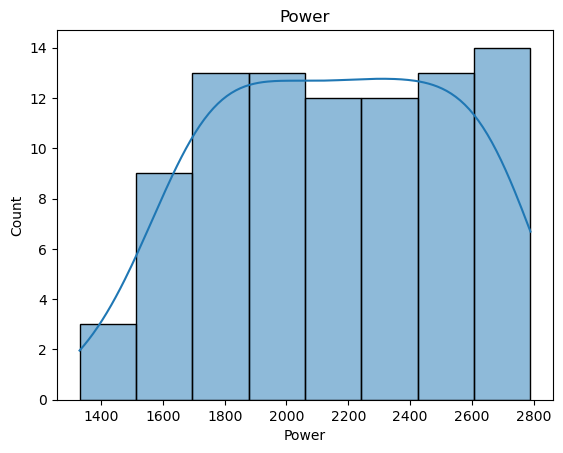

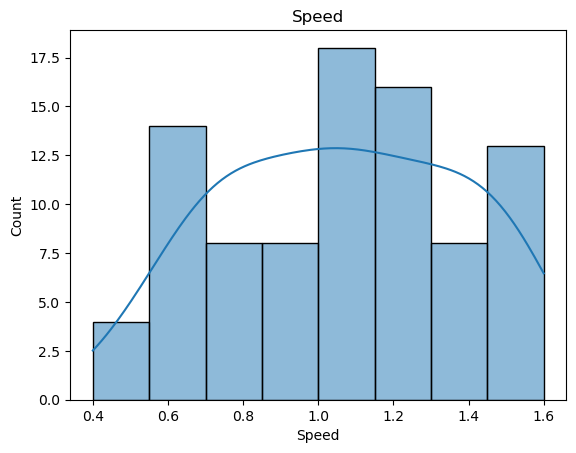

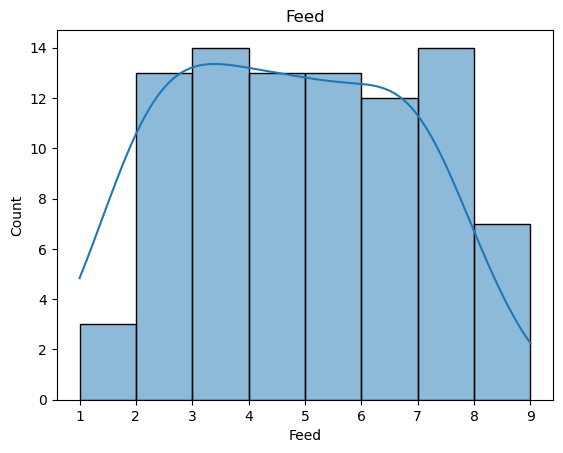

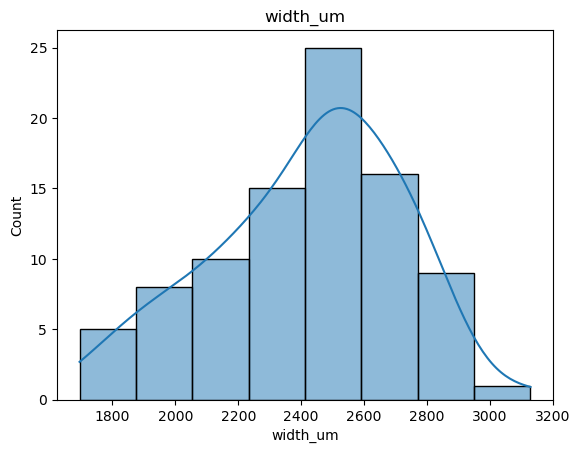

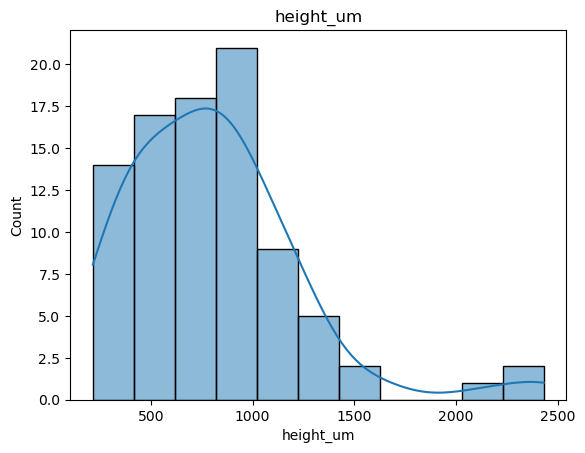

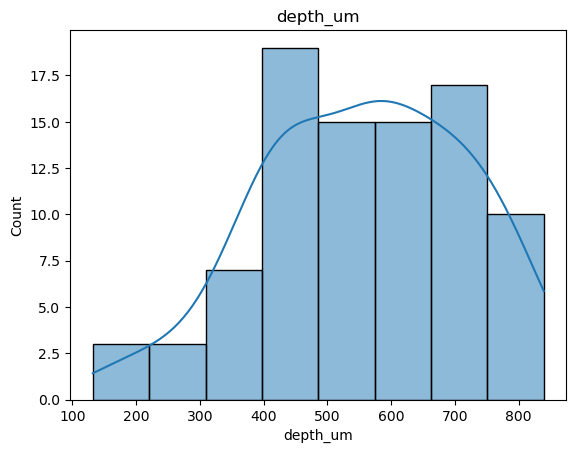

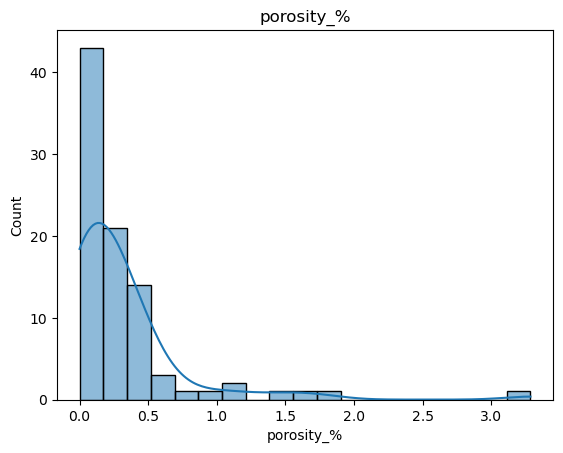

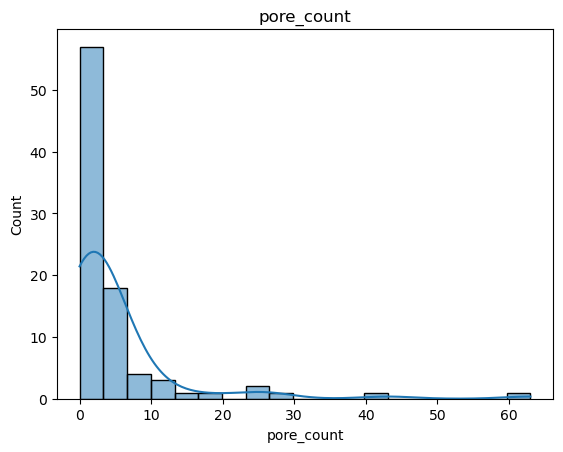

In [6]:
num_col = ["Power", "Speed", "Feed", "width_um", "height_um", "depth_um", "porosity_%", "pore_count" ]

for col in num_col:
    plt.figure()
    sns.histplot(df[col], kde = True)
    plt.title(col)

# Basic correlations and obvious LMD trends


Text(0.5, 1.0, 'correlation matrix')

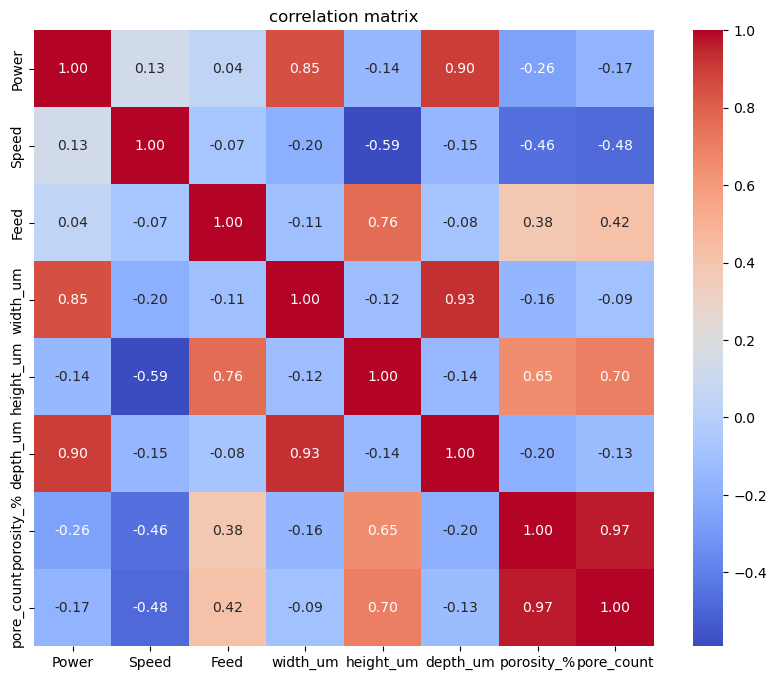

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(df[num_col].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("correlation matrix")

# Example physics check: Power vs Width, speed vs porosity

#sns.scatterplot(data=df, x= "Power", y="width_um")
#plt.show

#sns.scatterplot(data=df, x ="Speed", y= "porosity_%")
#plt.show


### Key findings from correlation matrix
## Strong positive correlations
1. Power <-> depth (0.90) : Higher power resulted in deeper penetration. 
  Explanation: More power increases heat input and melt pool depth. Depth is highly power-sensitive. This is a good sign; your experiment captured true causal physical behaviour.

2. Power <-> width (0.85) : Higher laser power -> wider meltpool -> wider clad
  Explanation: Increasing power increases energy density → more melting → lateral expansion of the molten zone → wider bead

3. Feed <-> Height (0.76):  Higher powder feed  -> Higher clad height
  Explanation: More powder delivered per unit time naturally increases volume per track → greater bead height. This is a direct control lever for maximizing clad height.

4. Width <-> Depth (0.93): Wide melt pools are generally deeper -> consistent with melt pool geometry

5. Height <-> porosity (0.65,0.7)
Explanation: This can indicate: Over-deposition trapping unfused particles, Instabilities in melt pool, Poor shielding when bead grows too tall. FURTHER INVESTIGATION REQUIRED

## Strong negative correlations
1. Speed <-> Height (-0.59): Increasing scan speed -> reduces clad height
Explanation:  Faster movement → less energy per unit length → lower melt pool stability → reduced bead buildup. Speed is a major inverse influencer of clad height.

2. Speed <-> Porosity (-0.46, -0.48): Higher speeds → lower pore count.
Possible reasons:Faster solidification → fewer entrapped gas bubbles. Smaller melt pool → fewer chances for pore growth.

## Scan speed may reduce porosity up to a point, but extreme speeds reduce melt pool stability.

This means that the three ["Power"] [Speed] [Feed] identified features are highly informatimative input features.

### THESIS INTERPRETATIONS

1. Correlation analysis reveals physically meaningful relationships consistent with melt pool thermodynamics.

2. Power strongly influences width and penetration depth, while powder feed predominantly controls clad height.

3. Scan speed demonstrates an inverse relationship with build-up, confirming reduced energy density at higher speeds.

4. Porosity metrics correlate positively with height, suggesting melt pool instability or insufficient fusion at higher deposition volumes.



In [7]:
#row with deep penetration
deep_rows = df[df["depth_um"]>1500]
print(deep_rows)

Empty DataFrame
Columns: [sample_id, Power, Speed, Feed, width_um, height_um, depth_um, angle_deg, porosity_%, pore_count, pore_area_um2, meltpool_area_um2, bbox_xyxy]
Index: []


# outlier detection amd physical justification

Goal: Systematically flag candidates and then decide, using LMD knowledge, whether to keep, cap, or investigate them.
Actions: Interquartile Range (IQR) ‑based outlier flags:A systematic, data-driven approach that helps identify potential outliers while allowing for domain knowledge intervention



In [8]:

outlier_flags = pd.DataFrame(index=df.index)

for col in num_col:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_flags[col + "_outlier"] = (df[col] < lower) | (df[col] > upper)

# How many outliers per column
outlier_flags.sum()

Power_outlier         0
Speed_outlier         0
Feed_outlier          0
width_um_outlier      0
height_um_outlier     3
depth_um_outlier      0
porosity_%_outlier    6
pore_count_outlier    7
dtype: int64

In [10]:
# looking at the columns where geometry or porosity is True

# Use only the columns that actually exist in outlier_flags
cols_of_interest = ["width_um", "height_um", "depth_um", "porosity_%", "pore_count"]
# Removed "pore_area_um2" since it doesn't have an outlier flag

mask_any = outlier_flags[[c + "_outlier" for c in cols_of_interest]].any(axis=1)
df_outliers = df.loc[mask_any, ["sample_id", "Power", "Speed", "Feed"] + cols_of_interest]
df_outliers


,sample_id,Power,Speed,Feed,width_um,height_um,depth_um,porosity_%,pore_count
56,60.0_P2560.0_V0.6_F_5.0,2560,0.6,5,2854.98,1182.95,798.75,0.885,19
62,66.0_P1680.0_V0.5_F_9.0,1680,0.5,9,1792.44,2395.82,280.22,1.038,26
67,70.0_P1440.0_V0.4_F_7.5,1440,0.4,7,1734.24,2432.18,132.18,1.407,24
68,71.0_P1540.0_V0.5_F_3.5,1540,0.5,3,2342.30,1094.51,364.86,1.149,15
69,72.0_P1860.0_V0.5_F_8.0,1860,0.5,8,2210.10,2120.35,380.68,1.766,43
71,74.0_P2000.0_V0.6_F_7.0,2000,0.6,7,2508.02,1607.46,534.01,3.285,63
72,75.0_P1830.0_V0.8_F_6.5,1830,0.8,6,2153.59,1300.91,505.54,1.575,27


In [13]:
# check for the excessive height

#row with deep penetration
high_rows = df[df["height_um"]>2000]
print(high_rows)

                  sample_id  Power  Speed  Feed  width_um  height_um  \
62  66.0_P1680.0_V0.5_F_9.0   1680    0.5     9   1792.44    2395.82   
67  70.0_P1440.0_V0.4_F_7.5   1440    0.4     7   1734.24    2432.18   
69  72.0_P1860.0_V0.5_F_8.0   1860    0.5     8   2210.10    2120.35   

    depth_um  angle_deg  porosity_%  pore_count  pore_area_um2  \
62    280.22     164.22       1.038          26        58904.4   
67    132.18     176.51       1.407          24        72253.0   
69    380.68     168.98       1.766          43        95076.4   

    meltpool_area_um2                                          bbox_xyxy  
62          5675533.5  [43.52288055419922, 118.65287017822266, 836.0,...  
67          5133772.0  [22.43105125427246, 153.08248901367188, 814.18...  
69          5384510.5  [12.07618522644043, 177.15386962890625, 815.82...  


### identified sample 66, 70, and 72 - Have clad height greater than 2000um. 

This can be justified by the high feed rate supplied to the clad, so it passes!


# Feature Engineering
Adding physics informed features such as LED, VED, AR, %Dilution


In [3]:
# Reading from the processed csv that I created using google colab. df will be DF

DF = pd.read_csv("~/Documents/PlayTime/LMD_Modelling/data/processed/processed_data.csv")

DF.head(10)

,sample_id,Power,Speed,Feed,width_um,LED_J_per_mm,VED_J_per_mm3,height_um,depth_um,angle_deg,...,dilution_percent,porosity_%,pore_count,pore_area_um2,meltpool_area_um2,bbox_xyxy,speed_mm_per_s,meltpool_area_mm2,A_height_um2,A_depth_um2
0,1.0_P1860.0_V1.1_F_2.0,1860,1.1,2,2288.60,101.454545,85.012065,294.92,476.93,179.92,...,61.790503,0.000,0,0.0,1193413.5,"[10.132645606994629, 390.0574035644531, 721.34...",18.333333,1.193413,674953.912,1.091502e+06
1,10.0_P2400.0_V1.5_F_4.5,2400,1.5,4,2480.80,96.000000,55.487128,488.73,583.10,-179.53,...,54.402284,0.000,0,0.0,1730131.0,"[63.66975402832031, 374.8359069824219, 826.238...",25.000000,1.730131,1212441.384,1.446554e+06
2,11.0_P1620.0_V0.9_F_3.0,1620,0.9,3,2039.20,108.000000,81.533734,547.71,416.26,179.72,...,43.181842,0.000,0,0.0,1324605.1,"[99.63111114501953, 375.4483947753906, 735.899...",15.000000,1.324605,1116890.232,8.488374e+05
3,12.0_P2470.0_V1.0_F_7.0,2470,1.0,7,2653.10,148.200000,45.516137,995.99,729.72,178.91,...,42.285204,0.491,7,16001.3,3255988.1,"[21.937089920043945, 213.30682373046875, 835.4...",16.666667,3.255988,2642461.069,1.936020e+06
4,13.0_P2440.0_V1.4_F_7.5,2440,1.4,7,2497.90,104.571429,43.237318,859.49,579.73,179.07,...,40.280847,0.000,0,0.0,2418545.7,"[34.45549774169922, 269.4804382324219, 835.095...",23.333333,2.418546,2146920.071,1.448108e+06
5,14.0_P2130.0_V1.2_F_7.5,2130,1.2,7,2393.09,106.500000,42.710811,963.97,468.51,179.84,...,32.706216,0.198,3,4947.5,2493513.9,"[49.24909973144531, 223.32098388671875, 813.46...",20.000000,2.493514,2306866.967,1.121187e+06
6,15.0_P2630.0_V0.8_F_5.0,2630,0.8,5,2787.84,197.250000,63.555970,839.26,788.71,179.03,...,48.447453,0.360,6,11178.8,3103563.7,"[0.0, 241.54849243164062, 827.6015014648438, 8...",13.333333,3.103564,2339722.598,2.198797e+06
7,16.0_P2750.0_V1.6_F_6.5,2750,1.6,6,2632.41,103.125000,43.950402,652.20,669.05,179.78,...,50.637654,0.086,1,2027.9,2346394.9,"[6.815893173217773, 307.4944152832031, 813.409...",26.666667,2.346395,1716857.802,1.761214e+06
8,17.0_P1670.0_V1.1_F_4.0,1670,1.1,4,1985.73,91.090909,66.448298,594.90,396.04,178.74,...,39.966093,0.500,2,6856.1,1370853.9,"[126.53072357177734, 300.4183044433594, 746.80...",18.333333,1.370854,1181310.777,7.864285e+05
9,18.0_P2080.0_V1.6_F_6.0,2080,1.6,6,2079.83,78.000000,50.190692,620.12,448.24,178.89,...,41.955895,0.250,2,3902.3,1554073.0,"[171.1734161376953, 337.8513488769531, 898.838...",26.666667,1.554073,1289744.180,9.322630e+05


In [4]:
DF.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89 entries, 0 to 88
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sample_id          89 non-null     object 
 1   Power              89 non-null     int64  
 2   Speed              89 non-null     float64
 3   Feed               89 non-null     int64  
 4   width_um           89 non-null     float64
 5   LED_J_per_mm       89 non-null     float64
 6   VED_J_per_mm3      89 non-null     float64
 7   height_um          89 non-null     float64
 8   depth_um           89 non-null     float64
 9   angle_deg          89 non-null     float64
 10  aspect_ratio       89 non-null     float64
 11  dilution_percent   89 non-null     float64
 12  porosity_%         89 non-null     float64
 13  pore_count         89 non-null     int64  
 14  pore_area_um2      89 non-null     float64
 15  meltpool_area_um2  89 non-null     float64
 16  bbox_xyxy          89 non-nu

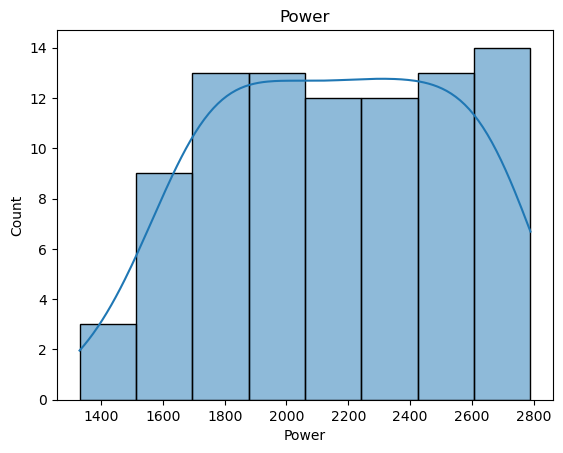

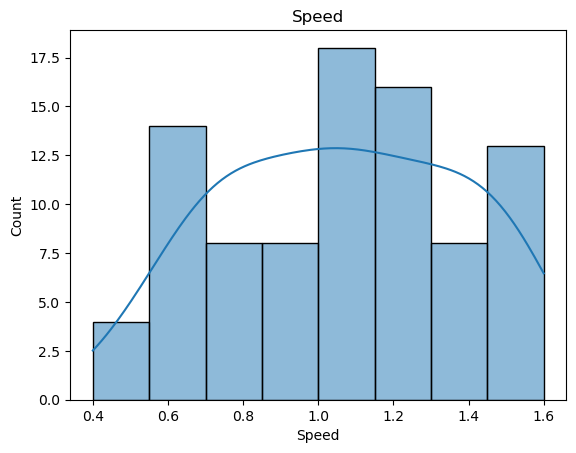

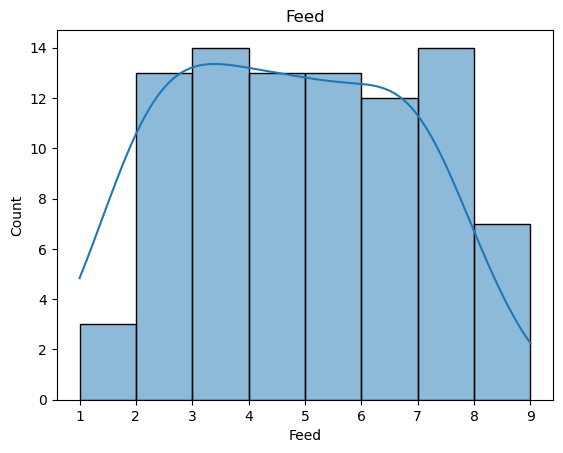

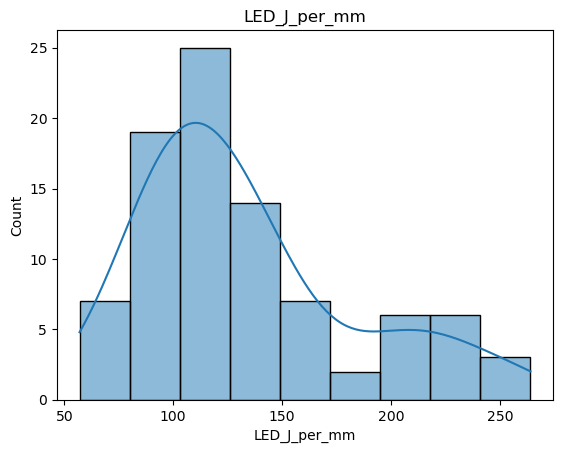

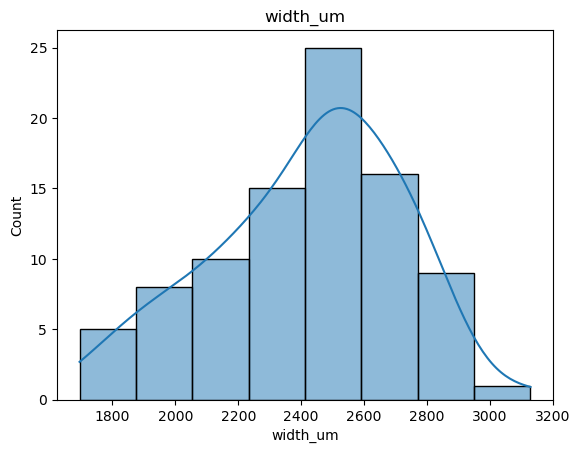

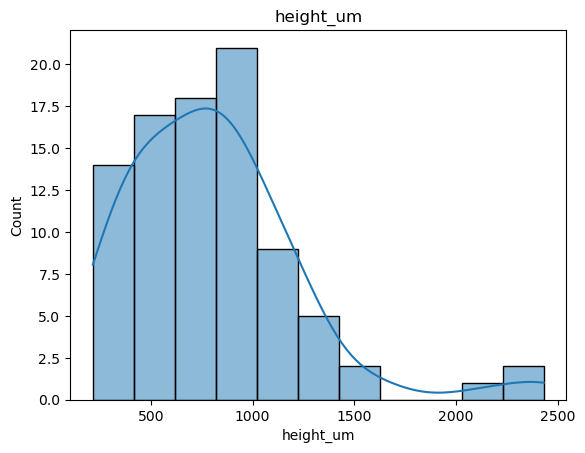

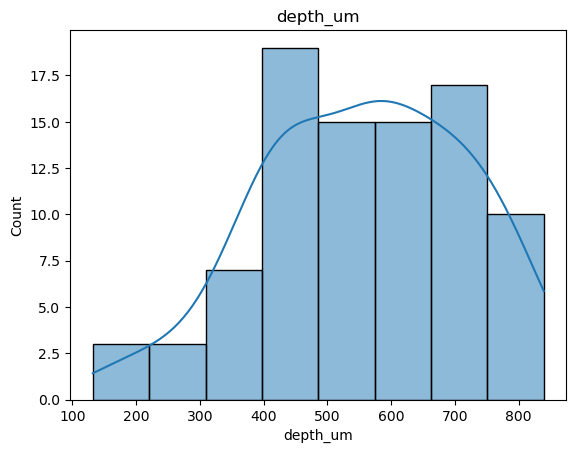

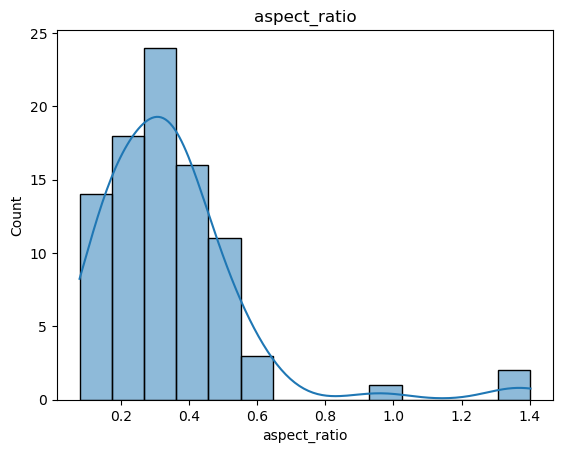

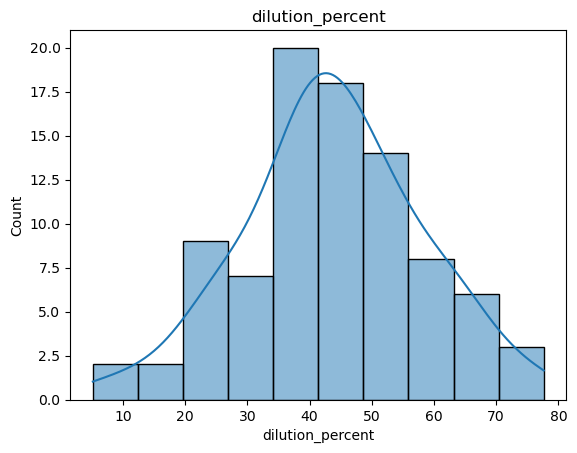

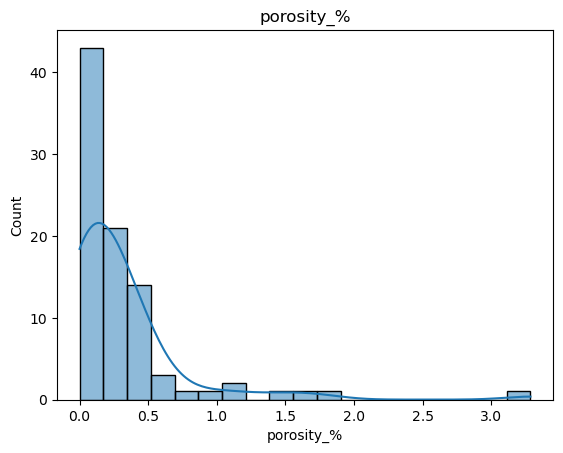

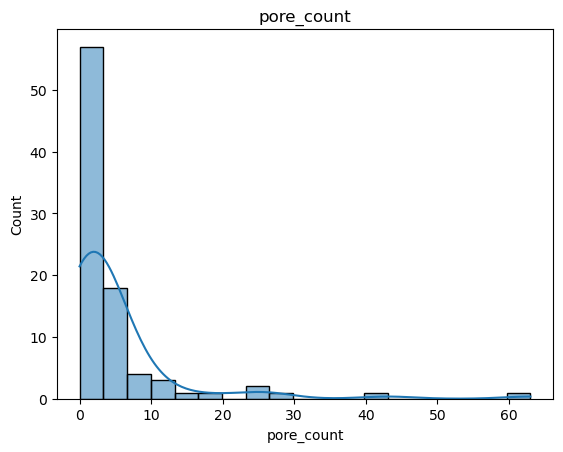

In [5]:
num_col = ["Power", "Speed", "Feed", "LED_J_per_mm", "width_um", "height_um", "depth_um", "aspect_ratio","dilution_percent",  "porosity_%", "pore_count" ]

for col in num_col:
    plt.figure()
    sns.histplot(DF[col], kde = True)
    plt.title(col)

Text(0.5, 1.0, 'Correlation Matrix with Engineered Features')

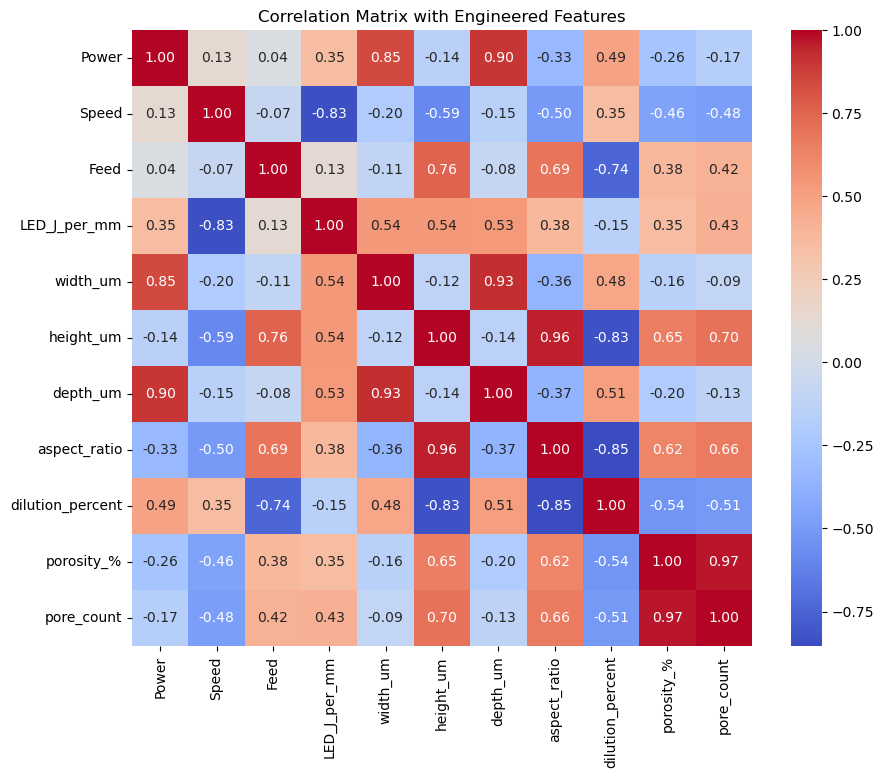

In [8]:
# Correlation plots with feature engineeering
plt.figure(figsize=(10,8))
sns.heatmap(DF[num_col].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix with Engineered Features")


# Key Takeaways

#### LED_J_per_mm (Linear Energy Density) 
-> Strong correlation with: "Speed = -0.83", "width_um = +0.54", "depth_um = +0.53"

Because LED is mathematically P/v, you expect strong negative correlation with speed. Physically, LED tracks heat input more robustly than raw power does.

### Aspect Ratio 
Extremely high correlation with: "height_um: 0.96", "porosity_%: 0.62", "pore_count: 0.66"

Aspect ratio encodes the relationship between bead height and width.
It is emerging as one of the strongest predictors for porosity and melt quality.

Aspect ratio is a strong, compact representation of geometric shape, reducing the need to use height and width separately.

### Dilution Percent
Strong negative correlation with: height_um and aspect_ratio

High dilution = more substrate melting, which tends to flatten the bead (low aspect ratio).

Dilution is a strong physical feature tied to quality and should be included unless it causes excessive multicollinearity with geometric parameters.

### What improved the most after engineering?
Mostly provided clarity where it was confusing

| Feature    | Before Engineering                       | After Engineering                 | Implication      |
| ---------- | ---------------------------------------- | --------------------------------- | ---------------- |
| Heat input | Power & Speed gave conflicting signals   | LED consolidates energy behaviour | Use LED          |
| Shape      | width, height, depth were multicollinear | aspect_ratio removes redundancy   | Use aspect_ratio |
| Metallurgy | no dilution metric existed               | dilution% reveals quality trends  | Use dilution%    |


# Final Feature Selection for Modelling

Based on statistical clarity and physical relevance:
These features add physics, reduce noise, and improve predictive power:
### Parameters
1. Power
2. Speed
3. Feed
4. LED_J_per_mm
### Features
5. aspect_ratio (compact geometry rep)
6. dilution_percent (quality metric)
7. Porosity (less so)
8. Height (target parameter)

In [9]:
DF.head()

,sample_id,Power,Speed,Feed,width_um,LED_J_per_mm,VED_J_per_mm3,height_um,depth_um,angle_deg,...,dilution_percent,porosity_%,pore_count,pore_area_um2,meltpool_area_um2,bbox_xyxy,speed_mm_per_s,meltpool_area_mm2,A_height_um2,A_depth_um2
0,1.0_P1860.0_V1.1_F_2.0,1860,1.1,2,2288.6,101.454545,85.012065,294.92,476.93,179.92,...,61.790503,0.000,0,0.0,1193413.5,"[10.132645606994629, 390.0574035644531, 721.34...",18.333333,1.193413,674953.912,1091501.998
1,10.0_P2400.0_V1.5_F_4.5,2400,1.5,4,2480.8,96.000000,55.487128,488.73,583.10,-179.53,...,54.402284,0.000,0,0.0,1730131.0,"[63.66975402832031, 374.8359069824219, 826.238...",25.000000,1.730131,1212441.384,1446554.480
2,11.0_P1620.0_V0.9_F_3.0,1620,0.9,3,2039.2,108.000000,81.533734,547.71,416.26,179.72,...,43.181842,0.000,0,0.0,1324605.1,"[99.63111114501953, 375.4483947753906, 735.899...",15.000000,1.324605,1116890.232,848837.392
3,12.0_P2470.0_V1.0_F_7.0,2470,1.0,7,2653.1,148.200000,45.516137,995.99,729.72,178.91,...,42.285204,0.491,7,16001.3,3255988.1,"[21.937089920043945, 213.30682373046875, 835.4...",16.666667,3.255988,2642461.069,1936020.132
4,13.0_P2440.0_V1.4_F_7.5,2440,1.4,7,2497.9,104.571429,43.237318,859.49,579.73,179.07,...,40.280847,0.000,0,0.0,2418545.7,"[34.45549774169922, 269.4804382324219, 835.095...",23.333333,2.418546,2146920.071,1448107.567


In [16]:
#sns.scatterplot(data=df, x="Power", y="porosity_%")
#plt.show()

